In [1]:
import sys
sys.path.append('../')

import numpy as np
import pickle

from weighted_conformal_clustering.utils import sample_gmm

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

### 2D Example with 5 Isotropic Components
(GMM2D5v1)

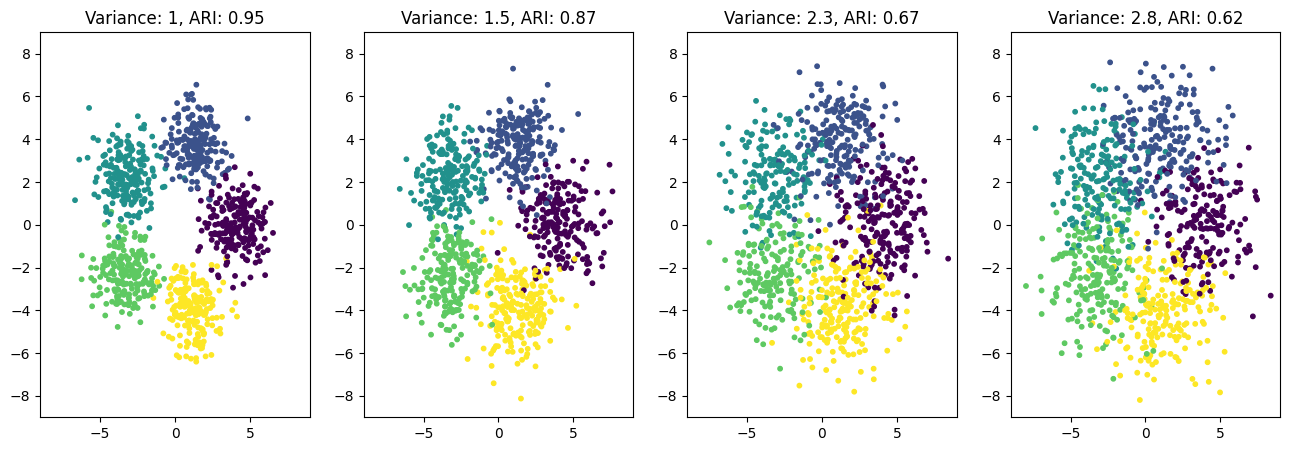

In [2]:
K = 5
d = 2

# generate means in 2D by equispaced points on a circle
means = 4 * np.vstack([np.cos(np.pi * np.linspace(0, 2, K, endpoint=False)),
                      np.sin(np.pi * np.linspace(0, 2, K, endpoint=False))]).T

base_covariances = np.array([np.eye(d) for _ in range(K)])
weights = np.ones(K) / K


var_range = [1, 1.5, 2.3, 2.8]

fig, axes = plt.subplots(1, len(var_range), figsize=(int(4*len(var_range)), 5))

for ax, var in zip(axes, var_range):
    covariances = base_covariances * var
    X, y = sample_gmm(means, covariances, weights, K*200)
    gmm = GaussianMixture(n_components=K, covariance_type='diag', random_state=0)
    gmm.fit(X)
    y_pred = gmm.predict(X)
    ari = adjusted_rand_score(y, y_pred)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=10)
    ax.set_title(f'Variance: {var}, ARI: {ari:.2f}')
    ax.set_xlim(-9, 9)
    ax.set_ylim(-9, 9)

plt.show()

### **Fixed Sample Size**

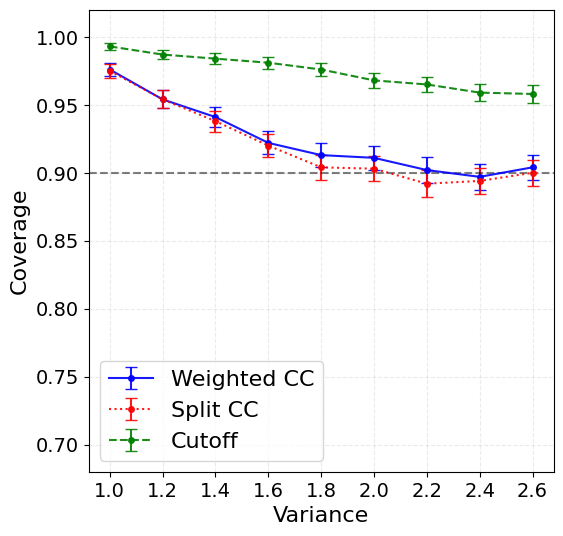

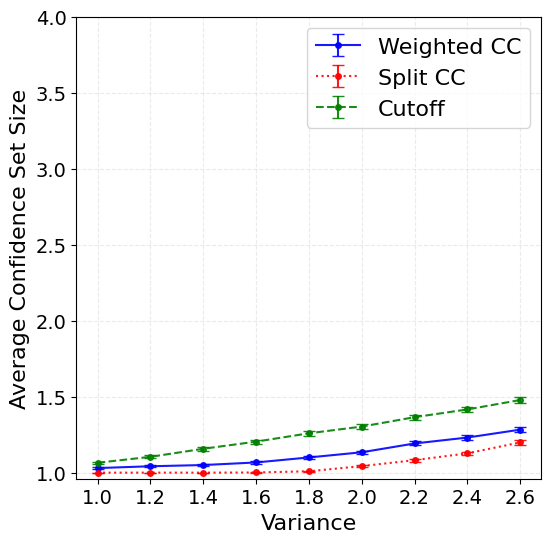

In [3]:
n = 1200
B = 1000
var_range = np.linspace(1, 2.6, 9)

with open(f'Results/GMM2D5v1kNN.pkl', 'rb') as f:
    results = pickle.load(f)
    
coverages = {'WeightedCC': [], 'SplitCC': [], 'Cutoff': []}
sizes = {'WeightedCC': [], 'SplitCC': [], 'Cutoff': []}

for method in ['WeightedCC', 'SplitCC', 'Cutoff']:
    cov, size = np.zeros((len(var_range), B)), np.zeros((len(var_range), B))
    for var_idx in range(len(var_range)):
        for b in range(B):
            res = results[var_idx*B + b]
            cov[var_idx, b], size[var_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    coverages[method] = (cov_mean, cov_se)
    sizes[method] = (size_mean, size_se)


# Errorbars with connected lines
plt.figure(figsize=(6,6))
plt.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.errorbar(var_range, coverages['Cutoff'][0], yerr=coverages['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.errorbar(var_range, sizes['Cutoff'][0], yerr=sizes['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.1f}" for v in var_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 4.0))
plt.show()

### **Asymptotic: Increasing Sample Size**

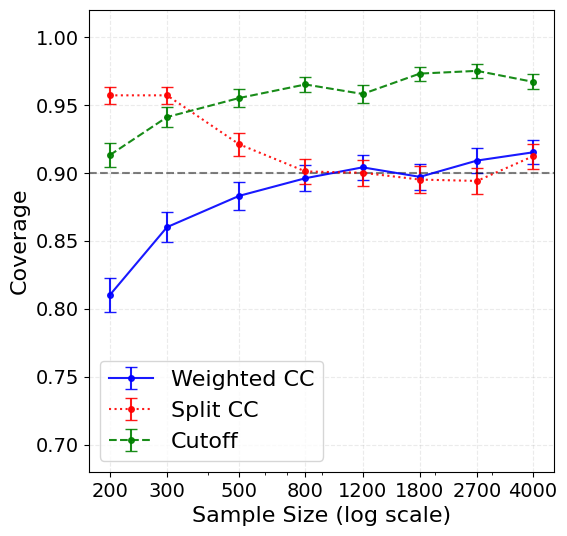

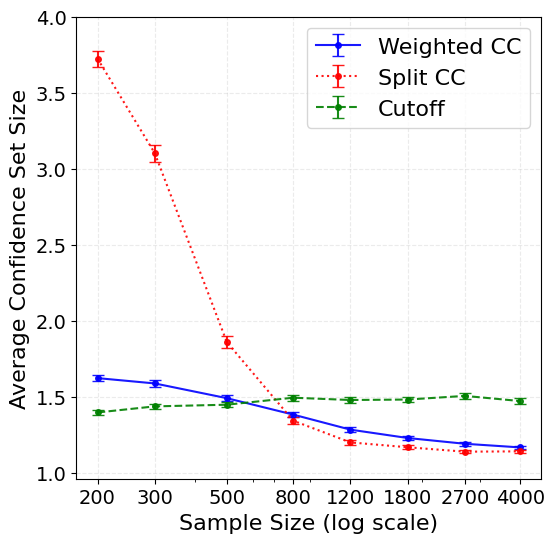

In [4]:
var = 2.6
B = 1000
n_range = [200, 300, 500, 800, 1200, 1800, 2700, 4000]

with open(f'Results/GMM2D5v1kNN_asymp.pkl', 'rb') as f:
    results = pickle.load(f)

asymp_coverages = {'WeightedCC': [], 'SplitCC': [], 'Cutoff': []}
asymp_sizes = {'WeightedCC': [], 'SplitCC': [], 'Cutoff': []}

for method in ['WeightedCC', 'SplitCC', 'Cutoff']:
    cov, size = np.zeros((len(n_range), B)), np.zeros((len(n_range), B))
    for n_idx in range(len(n_range)):
        for b in range(B):
            res = results[n_idx*B + b]
            cov[n_idx, b], size[n_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    asymp_coverages[method] = (cov_mean, cov_se)
    asymp_sizes[method] = (size_mean, size_se)
    

# Errorbars with connected lines (x-axis = sample size in log scale)
plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.errorbar(n_range, asymp_coverages['Cutoff'][0], yerr=asymp_coverages['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.68, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.errorbar(n_range, asymp_sizes['Cutoff'][0], yerr=asymp_sizes['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 4.0))
plt.show()

### Combined Figures

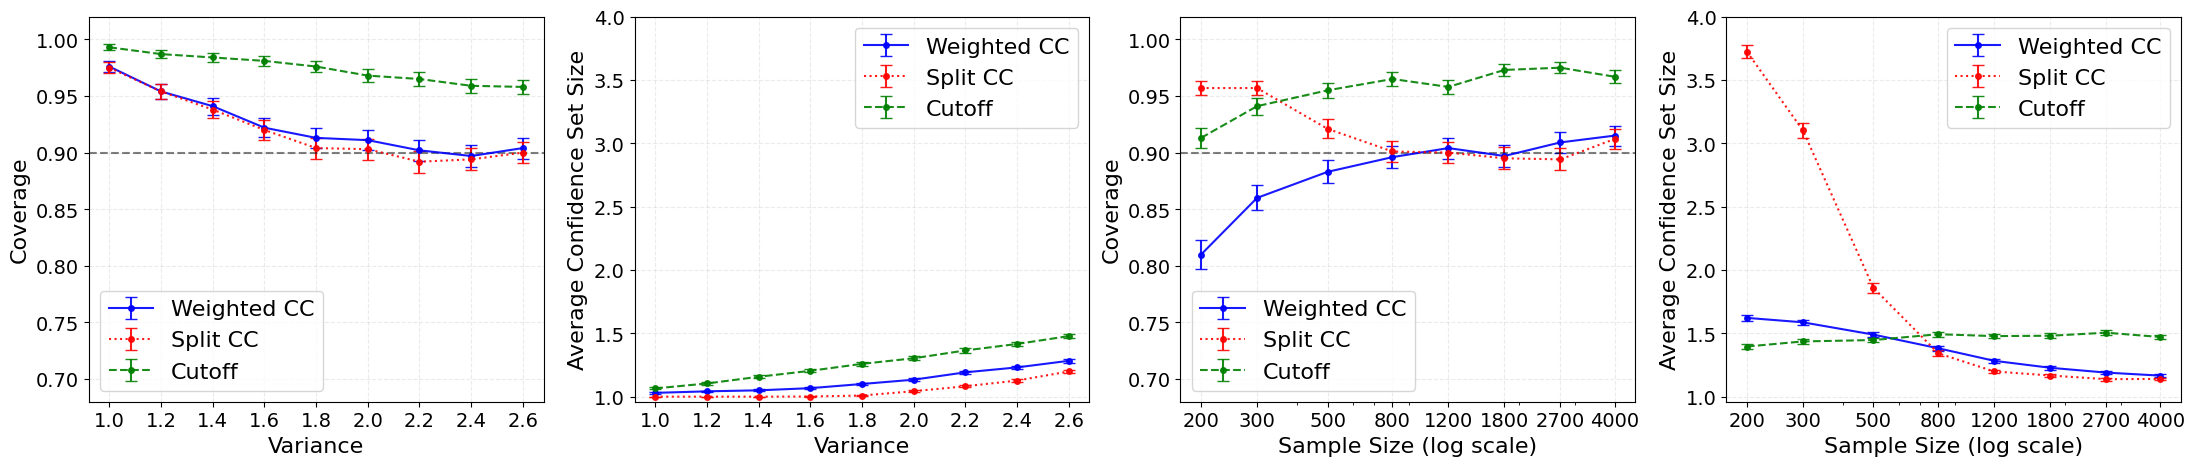

In [5]:
fig = plt.figure(figsize=(27, 5))
gs = GridSpec(nrows=1, ncols=4, figure=fig, wspace=0.2, hspace=0.2)

# Coverage (fixed sample size)
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax1.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax1.errorbar(var_range, coverages['Cutoff'][0], yerr=coverages['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
ax1.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Variance', fontsize=16)
ax1.set_xticks(var_range)
ax1.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax1.set_ylabel('Coverage', fontsize=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(fontsize=16)
ax1.grid(True, linestyle="--", alpha=0.25)
ax1.set_ylim((0.68, 1.02))

# Size (fixed sample size)
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax2.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax2.errorbar(var_range, sizes['Cutoff'][0], yerr=sizes['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
ax2.set_xlabel('Variance', fontsize=16)
ax2.set_xticks(var_range)
ax2.set_xticklabels(labels=[f"{v:.1f}" for v in var_range], fontsize=14)
ax2.set_ylabel('Average Confidence Set Size', fontsize=16)
ax2.tick_params(axis='y', labelsize=14)
ax2.legend(fontsize=16)
ax2.grid(True, linestyle="--", alpha=0.25)
ax2.set_ylim((0.96, 4.0))

# Asymptotic coverage
ax3 = fig.add_subplot(gs[0, 2])
ax3.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax3.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax3.errorbar(n_range, asymp_coverages['Cutoff'][0], yerr=asymp_coverages['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
ax3.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax3.set_xlabel('Sample Size (log scale)', fontsize=16)
ax3.set_xscale('log')
ax3.set_xticks(n_range)
ax3.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax3.set_ylabel('Coverage', fontsize=16)
ax3.tick_params(axis='y', labelsize=14)
ax3.legend(fontsize=16)
ax3.grid(True, linestyle="--", alpha=0.25)
ax3.set_ylim((0.68, 1.02))

# Asymptotic size
ax4 = fig.add_subplot(gs[0, 3])
ax4.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax4.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax4.errorbar(n_range, asymp_sizes['Cutoff'][0], yerr=asymp_sizes['Cutoff'][1], fmt='go--', capsize=4, markersize=4, alpha=0.9, label='Cutoff')
ax4.set_xlabel('Sample Size (log scale)', fontsize=16)
ax4.set_xscale('log')
ax4.set_xticks(n_range)
ax4.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax4.set_ylabel('Average Confidence Set Size', fontsize=16)
ax4.tick_params(axis='y', labelsize=14)
ax4.legend(fontsize=16)
ax4.grid(True, linestyle="--", alpha=0.25)
ax4.set_ylim((0.96, 4.0))

plt.savefig('Figures/GMM2D5v1kNN.pdf', bbox_inches='tight')
plt.show()

In [21]:
from weighted_conformal_clustering.utils import WeightedConformalClustering, label_alignment
import matplotlib.colors as mcolors
from joblib import Parallel, delayed


# Core colors
core_hex = {
    2: "#64EDFF83",  # blue
    4: "#FDFF8D",  # yellow
    0: "#2ECC40",  # green
    1: "#FF810B",  # orange
    3: "#B10DC9",  # purple
    5: "#FF0000",  # red
}
core_rgb = {k: np.array(mcolors.to_rgb(v), float) for k, v in core_hex.items()}

# Define dark colors for training points
def darken(rgb, factor=0.15):  # 0.15 = 15% darker
    return np.clip(rgb * (1 - factor), 0, 1)

dark_colors = {k: darken(core_rgb[k], 0.15) for k in core_rgb}

def lighten_toward_white(rgb, alpha):
    """alpha in [0,1]: 0 = no change, 1 = white."""
    return (1 - alpha) * rgb + alpha * 1.0

def labels_to_color(labels_like, n_classes=5, base_alpha=0.05):
    """
    - If labels_like is an int -> use that core color.
    - If it's an iterable -> take the mean of the cores in it,
      then 'intensify by number of labels' by moving toward white
      with alpha = base_alpha * (k-1), where k = set size.
      (More labels -> lighter background.)
    """
    # normalize to a Python set of ints
    if isinstance(labels_like, (int, np.integer)):
        S = {int(labels_like)}
    else:
        S = {int(x) for x in labels_like}

    # empty set -> white
    if len(S) == 0:
        return np.array([1.0, 1.0, 1.0], float)

    # mean of the present cores
    mean_rgb = np.mean([core_rgb[i] for i in S], axis=0)

    # intensity control by subset size k
    k = len(S)
    alpha = min(1.0, base_alpha * (k - 1))  # more labels -> lighter
    return lighten_toward_white(mean_rgb, alpha)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1900 tasks      | elapsed:    3.6s
[Parallel(n_jobs=-1)]: Done 4835 tasks      | elapsed:    8.7s
[Parallel(n_jobs=-1)]: Done 4900 out of 4900 | elapsed:    8.8s finished


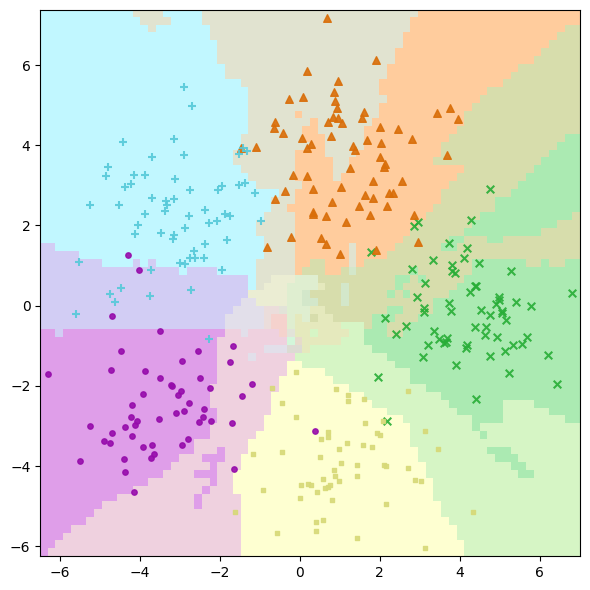

In [31]:
n = 300
var = 1.4
covariances = base_covariances * var
X, y = sample_gmm(means, covariances, weights, n_samples=n, seed=2)

X_tr, y_tr = X[:(n//2)], y[:(n//2)] # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration

wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2)))
wcc.train('GMMS', n_components=K, max_iter=200, n_init=5, random_state=0)

# ---- grid over the 2D plane (same for all methods) ---
x_min = X[:,0].min() - 0.2
x_max = X[:,0].max() + 0.2
y_min = X[:,1].min() - 0.2
y_max = X[:,1].max() + 0.2

res = 70
x_range = np.linspace(x_min, x_max, res)
y_range = np.linspace(y_min, y_max, res)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel())) # flattened grid points

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'GMMS', n_components=K, max_iter=200, n_init=5, random_state=0)
    for i in range(grid_points.shape[0])
)

oracle_alignment = label_alignment(y_tr, wcc.y_tr, K) # oracle alignment
color_grid = np.array([labels_to_color(oracle_alignment[predictions_boolean[i]]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

plt.figure(figsize=(6,6))
plt.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)
for label in range(K):
    mask = (y == label)
    marker_size = 30
    if label == 0:
        marker = 'x'
    elif label == 1:
        marker = '^'
    elif label == 2:
        marker = '+'
    elif label == 3:
        marker = 'o'
        marker_size = 15
    else:
        marker = 's'
        marker_size = 12

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        color=dark_colors[label],
        s=marker_size,
        alpha=0.9, 
        marker=marker
    )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
#plt.savefig('Figures/GMM2D3v1_heatmap1.pdf', bbox_inches='tight')
plt.show()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1900 tasks      | elapsed:    3.5s
[Parallel(n_jobs=-1)]: Done 4850 tasks      | elapsed:    8.8s
[Parallel(n_jobs=-1)]: Done 4900 out of 4900 | elapsed:    8.8s finished


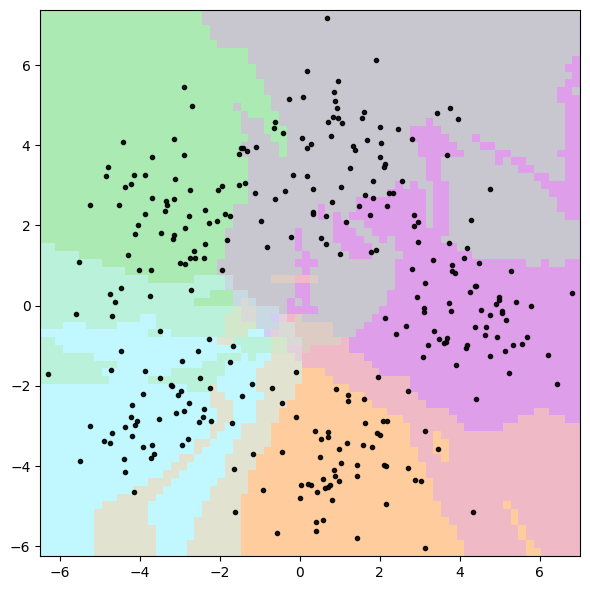

In [32]:
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2)))
wcc.train('GMMS', n_components=K-1, max_iter=200, n_init=5, random_state=0)

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'GMMS', n_components=K-1, max_iter=200, n_init=5, random_state=0)
    for i in range(grid_points.shape[0])
)

color_grid = np.array([labels_to_color(predictions_boolean[i]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

plt.figure(figsize=(6,6))
plt.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.9, 
    color='k',
    marker='.',
)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
#plt.savefig('Figures/GMM2D3v1_heatmap1.pdf', bbox_inches='tight')
plt.show()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    3.4s
[Parallel(n_jobs=-1)]: Done 3100 tasks      | elapsed:    9.1s
[Parallel(n_jobs=-1)]: Done 4900 out of 4900 | elapsed:   14.1s finished


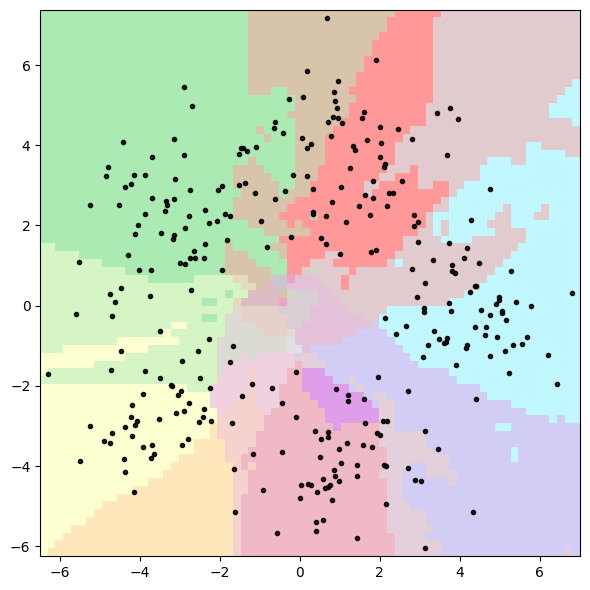

In [33]:
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2)))
wcc.train('GMMS', n_components=K+1, max_iter=200, n_init=5, random_state=0)

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'GMMS', n_components=K+1, max_iter=200, n_init=5, random_state=0)
    for i in range(grid_points.shape[0])
)

color_grid = np.array([labels_to_color(predictions_boolean[i]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

plt.figure(figsize=(6,6))
plt.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.9, 
    color='k',
    marker='.',
)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
#plt.savefig('Figures/GMM2D3v1_heatmap1.pdf', bbox_inches='tight')
plt.show()